# Scrap gap to 2030

How much scrap will the EU still have to export in 2030 if the announced electric arc furnaces start?

2025 consumption 74.4 Mt is from Eurofer (S&P Global, 30 Sep 2026):
https://www.spglobal.com/energy/en/news-research/latest-news/metals/093026-europes-scrap-demand-set-to-surge-as-new-eafs-loom-eurofer

In [1]:
import numpy as np
import pandas as pd
from pandas import DataFrame
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set()

## 2025 balance

In [2]:
balance = pd.read_csv('../data/processed/scrap_balance_annual.csv')
trade = pd.read_csv('../data/processed/fact_trade_monthly.csv', dtype={'product': str})

exp25 = trade[(trade['product'] == '7204') & (trade['flow'] == 'export') & (trade['year'] == 2025)]

consumption_2025 = 74.4
net_exports_2025 = balance.loc[balance['year'] == 2025, 'net_exports_mt'].values[0]
oecd_2025 = exp25[exp25['partner_group'] == 'OECD']['tonnes'].sum() / 1e6
non_oecd_2025 = exp25[exp25['partner_group'] == 'non-OECD']['tonnes'].sum() / 1e6
available_2025 = consumption_2025 + net_exports_2025

print(f'Consumption 2025: {consumption_2025:.1f} Mt')
print(f'Net exports 2025: {net_exports_2025:.1f} Mt')
print(f'Available scrap 2025: {available_2025:.1f} Mt')
print(f'Exports to OECD: {oecd_2025:.1f} Mt, to non-OECD: {non_oecd_2025:.1f} Mt')

Consumption 2025: 74.4 Mt
Net exports 2025: 10.9 Mt
Available scrap 2025: 85.3 Mt
Exports to OECD: 11.4 Mt, to non-OECD: 4.4 Mt


## EAF projects
I made this list from company announcements and news (link in `source_url`). scrap_share and replaces_bof are my assumptions from the announced feed mix.

In [3]:
tracker = pd.read_csv('../data/raw/eaf_project_tracker.csv')

tracker['scrap_share'] = [.85, .60, .60, .85, .60, .40, .60, .60, .20, .60, .85, .85, .60, .40, .60, .40, .60, .20, .85]
tracker['replaces_bof'] = [0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1]

tracker[['company', 'site', 'eaf_capacity_mt', 'start_year', 'confidence', 'scrap_share', 'replaces_bof']]

,company,site,eaf_capacity_mt,start_year,confidence,scrap_share,replaces_bof
0,ArcelorMittal,Gijon,1.10,2026,medium,0.85,0
1,voestalpine,Linz,1.60,2027,high,0.60,1
2,voestalpine,Donawitz,0.85,2027,high,0.60,1
3,SSAB,Oxelosund,1.50,2027,medium,0.85,1
4,SSAB,Lulea,2.50,2028,high,0.60,1
5,Salzgitter,Salzgitter (SALCOS stage 1),1.90,2027,medium,0.40,1
6,Salzgitter (HKM),Duisburg,2.50,2029,high,0.60,1
7,ArcelorMittal,Dunkirk,2.00,2029,high,0.60,1
8,Stegra,Boden,2.50,2027,medium,0.20,0
9,Metinvest,Piombino,2.70,2028,low,0.60,0


In [4]:
print('Capacity starting 2026-2030: {:.1f} Mt'.format(tracker[tracker['start_year'] <= 2030]['eaf_capacity_mt'].sum()))
print('Eurofer figure: 44.1 Mt announced, of which 33.8 Mt progressing')
tracker.pivot_table(index='start_year', columns='confidence', values='eaf_capacity_mt', aggfunc='sum').fillna(0)

Capacity starting 2026-2030: 33.9 Mt
Eurofer figure: 44.1 Mt announced, of which 33.8 Mt progressing


confidence,high,low,medium
start_year,,,
2026,0.00,0.0,1.10
2027,2.45,0.0,5.90
2028,2.50,5.3,1.75
2029,4.50,0.0,1.75
2030,0.00,8.6,0.00
2031,0.00,2.6,0.00


## Scenarios
- Slow: only high/medium confidence projects, 1 year late, 70% utilisation
- Base: all projects, low confidence ones 2 years late, 80% utilisation
- Fast: all projects on time, 85% utilisation, plus 5 Mt extra scrap demand to replace lost steel imports, collection +1.5%/yr

Other assumptions: 1.1 t metallics per t steel, BOF uses 0.18 t scrap per t steel, first year at 40%, collection +1%/yr.

In [5]:
years = range(2025, 2031)

scenarios = {
    'Slow': {'conf': ['high', 'medium'], 'delay': 1, 'delay_low': 0, 'util': 0.70, 'import_sub': 0, 'collect': 0.010},
    'Base': {'conf': ['high', 'medium', 'low'], 'delay': 0, 'delay_low': 2, 'util': 0.80, 'import_sub': 0, 'collect': 0.010},
    'Fast': {'conf': ['high', 'medium', 'low'], 'delay': 0, 'delay_low': 0, 'util': 0.85, 'import_sub': 5, 'collect': 0.015}}

def run_scenario(s):
    p = tracker[tracker['confidence'].isin(s['conf']) & tracker['eaf_capacity_mt'].notnull()].copy()
    p['start'] = p['start_year'] + np.where(p['confidence'] == 'low', s['delay_low'], s['delay'])
    rows = []
    for y in years:
        live = p[p['start'] <= y]
        steel = live['eaf_capacity_mt'] * s['util'] * np.where(live['start'] == y, 0.4, 1.0)
        new_scrap = (steel * 1.10 * live['scrap_share'] - steel * 0.18 * live['replaces_bof']).sum()
        import_sub = 0 if y == 2025 else (s['import_sub'] / 2 if y == 2026 else s['import_sub'])
        rows.append([y, new_scrap, import_sub])
    res = DataFrame(rows, columns=['year', 'new_eaf_scrap_mt', 'import_substitution_mt'])
    res['new_eaf_scrap_mt'] = res['new_eaf_scrap_mt'] - res['new_eaf_scrap_mt'].iloc[0]
    res['consumption_mt'] = consumption_2025 + res['new_eaf_scrap_mt'] + res['import_substitution_mt']
    res['availability_mt'] = available_2025 * (1 + s['collect']) ** (res['year'] - 2025)
    res['exportable_surplus_mt'] = res['availability_mt'] - res['consumption_mt']
    return res

results = pd.concat([run_scenario(s).assign(scenario=name) for name, s in scenarios.items()])
results.pivot(index='year', columns='scenario', values='exportable_surplus_mt')

scenario,Base,Fast,Slow
year,,,
2025,10.933084,10.933084,10.933084
2026,11.457295,9.363391,11.786415
2027,10.752679,6.498202,12.360299
2028,9.361162,3.981091,11.860112
2029,8.424350,1.241426,10.760050
2030,6.708969,0.317037,10.059029


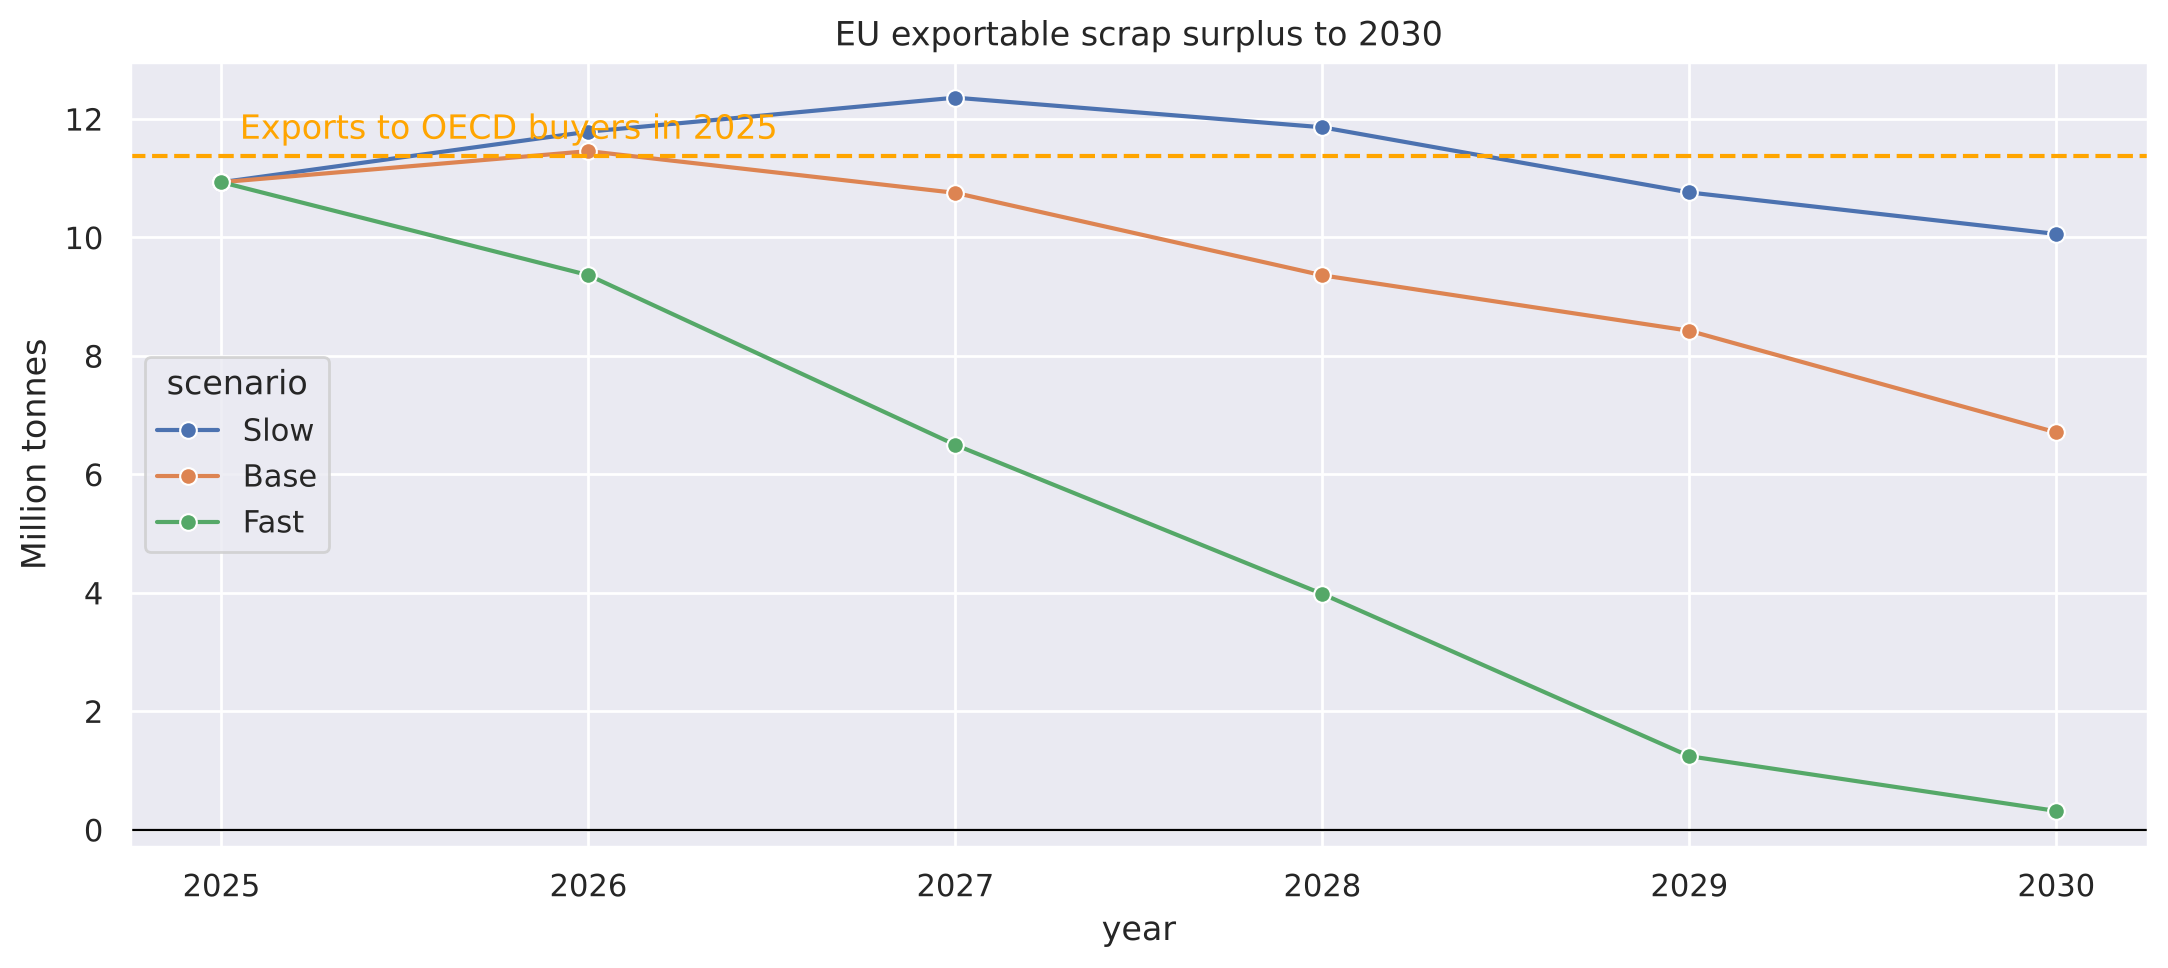

In [6]:
plt.figure(figsize=(11, 5))
sns.lineplot(data=results, x='year', y='exportable_surplus_mt', hue='scenario', marker='o')
plt.axhline(oecd_2025, color='orange', linestyle='--')
plt.text(2025.05, oecd_2025 + 0.3, 'Exports to OECD buyers in 2025', color='orange')
plt.axhline(0, color='black', linewidth=0.8)
plt.title('EU exportable scrap surplus to 2030')
plt.ylabel('Million tonnes')
plt.tight_layout()
plt.savefig('../outputs/figures/06_surplus_scenarios.png')
plt.show()

## Sensitivity (2030, base case)

In [7]:
def surplus_2030(**change):
    s = dict(scenarios['Base'])
    s.update(change)
    return run_scenario(s)['exportable_surplus_mt'].iloc[-1]

sens = DataFrame([
    ['Utilisation 70% / 90%', surplus_2030(util=0.70), surplus_2030(util=0.90)],
    ['Collection growth 0% / 2%', surplus_2030(collect=0.0), surplus_2030(collect=0.02)],
    ['Import substitution 0 / 6 Mt', surplus_2030(import_sub=0), surplus_2030(import_sub=6)],
    ['Low-confidence projects on time / dropped', surplus_2030(delay_low=0), surplus_2030(conf=['high', 'medium'])]],
    columns=['driver', 'low_case', 'high_case'])
sens['swing'] = (sens['low_case'] - sens['high_case']).abs()
sens = sens.sort_values('swing')
sens

,driver,low_case,high_case,swing
0,Utilisation 70% / 90%,7.781089,5.636849,2.144240
3,Low-confidence projects on time / dropped,3.793289,8.057129,4.263840
2,Import substitution 0 / 6 Mt,6.708969,0.708969,6.000000
1,Collection growth 0% / 2%,2.356124,11.237660,8.881536


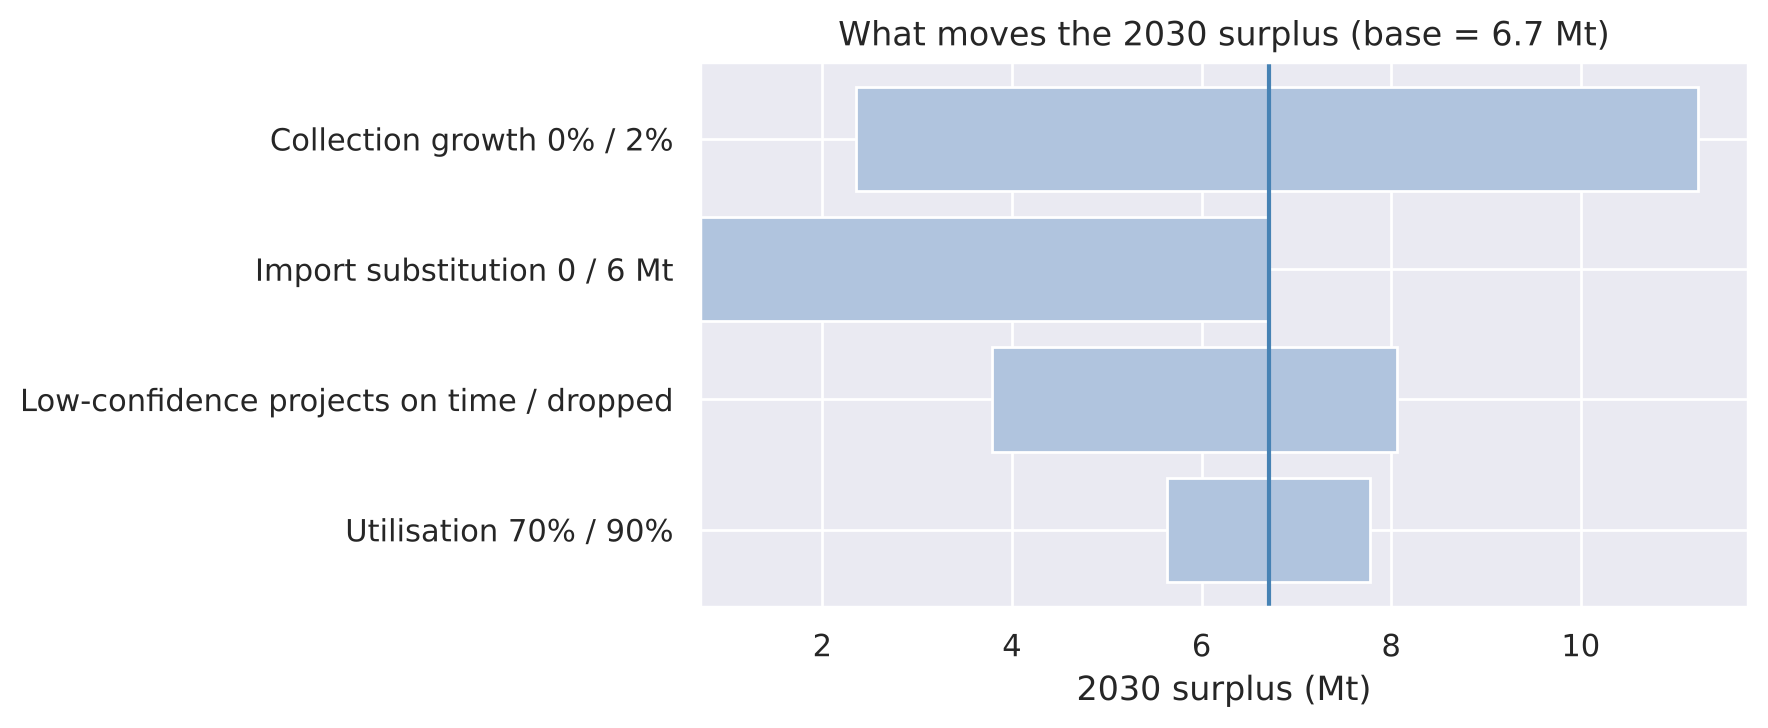

In [8]:
base_2030 = surplus_2030()

plt.figure(figsize=(9, 3.8))
for i, r in enumerate(sens.itertuples()):
    lo, hi = sorted([r.low_case, r.high_case])
    plt.barh(i, hi - lo, left=lo, color='lightsteelblue')
plt.axvline(base_2030, color='steelblue')
plt.yticks(range(len(sens)), sens['driver'])
plt.xlabel('2030 surplus (Mt)')
plt.title('What moves the 2030 surplus (base = {:.1f} Mt)'.format(base_2030))
plt.tight_layout()
plt.savefig('../outputs/figures/07_sensitivity.png')
plt.show()

In [9]:
results.to_csv('../data/processed/scenario_surplus.csv', index=False)
tracker.to_csv('../data/processed/dim_eaf_projects.csv', index=False)